**병합 안내:** 코드 셀은 `main`의 최신 CSV/ZIP 경로 처리 변경을 적용했습니다. 보존된 실행 출력은 이전 `feature/frontend` 실행 결과이므로 수정된 코드 기준으로 재실행하여 확인하세요.

# EDA — 250m 생활인구 데이터

## 1. 데이터 구조 및 품질
## 2. 전처리 및 파생변수
## 3. 기초 통계 및 시각화
## 4. 결과 저장 및 검증

원본 크기: (254590, 33)


,일자,시간,행정동코드,250M격자,생활인구합계,남자 0~9세,남자 10~14세,남자 15~19세,남자 20~24세,남자 25~29세,...,여자 25~29세,여자 30~34세,여자 35~39세,여자 40~44세,여자 45~49세,여자 50~54세,여자 55~59세,여자 60~64세,여자 65~69세,여자 70세 이상
0,20261027,0,11110515,다사52255325,7.29,*,*,*,*,*,...,*,*,*,*,*,*,*,*,*,*
1,20261027,0,11110515,다사52255350,8.98,*,*,*,*,*,...,*,*,*,*,*,*,*,*,*,*
2,20261027,0,11110515,다사52255375,19.53,*,*,*,*,*,...,*,*,*,*,*,*,*,*,*,*
3,20261027,0,11110515,다사52505325,28.79,*,*,*,*,*,...,*,*,*,*,*,*,*,*,*,*
4,20261027,0,11110515,다사52505350,860.99,*,12.64,11.28,11.13,29.92,...,11.11,39.13,55.3,20.07,58.92,57.97,34.97,21.59,47.4,81.66


C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:77: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.title("시간대별 250m 격자 생활인구합계 평균"); plt.xlabel("시간"); plt.ylabel("평균"); plt.tight_layout(); plt.show()
C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:77: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.title("시간대별 250m 격자 생활인구합계 평균"); plt.xlabel("시간"); plt.ylabel("평균"); plt.tight_layout(); plt.show()
C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:77: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  plt.title("시간대별 250m 격자 생활인구합계 평균"); plt.xlabel("시간"); plt.ylabel("평균"); plt.tight_layout(); plt.show()
C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:77: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  plt.title("시간대별 250m 격자 생활인구합계 평균"); plt.xlabel("시간"); plt.ylabel("평균"); 

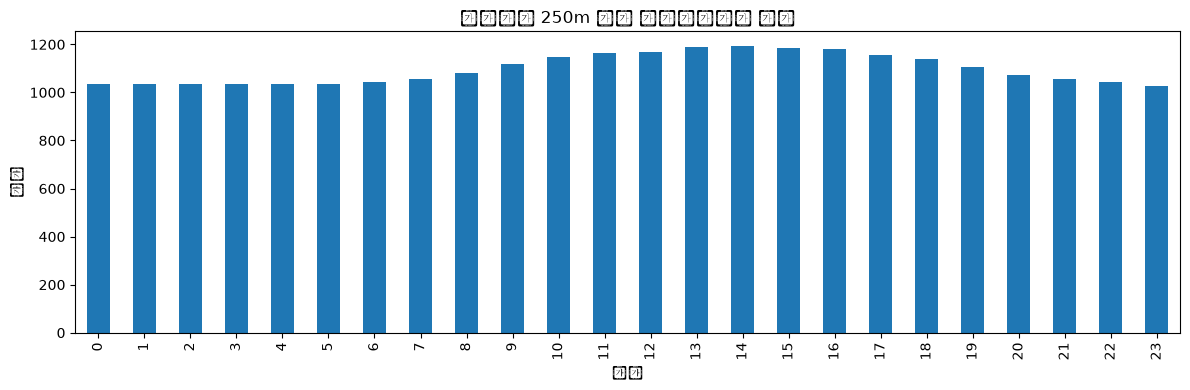

C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:79: UserWarning: Glyph 49373 (\N{HANGUL SYLLABLE SAENG}) missing from font(s) DejaVu Sans.
  plt.title("생활인구합계 분포"); plt.xlabel("생활인구합계"); plt.tight_layout(); plt.show()
C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:79: UserWarning: Glyph 54876 (\N{HANGUL SYLLABLE HWAL}) missing from font(s) DejaVu Sans.
  plt.title("생활인구합계 분포"); plt.xlabel("생활인구합계"); plt.tight_layout(); plt.show()
C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:79: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  plt.title("생활인구합계 분포"); plt.xlabel("생활인구합계"); plt.tight_layout(); plt.show()
C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:79: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.title("생활인구합계 분포"); plt.xlabel("생활인구합계"); plt.tight_layout(); plt.show()
C:\Users\asia\AppData\Local\Temp\ipykernel_4208\4185130406.py:79: UserWarning: 

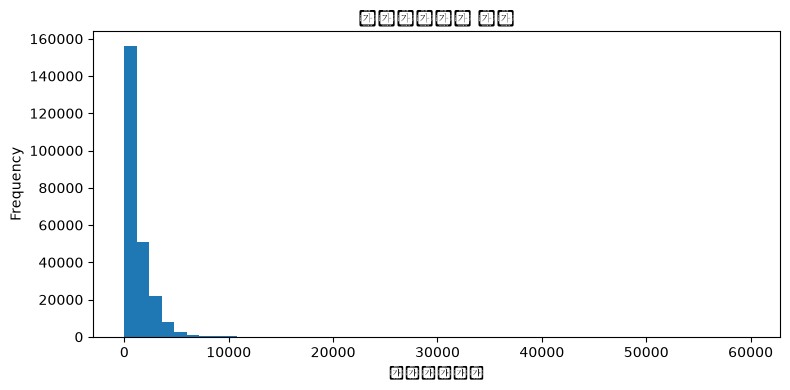

전처리 후: (254590, 66) summary: (9033, 7) features: (254590, 42)
완전중복: 0 복합키중복: 0
별표 표시 셀: 2917989


In [3]:

from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile

# Drive에서 복사한 data/raw_data 아래의 CSV 또는 CSV가 포함된 ZIP을 찾습니다.
def find_population_source(raw_root, csv_filename):
    if not raw_root.is_dir():
        raise FileNotFoundError(f"원본 데이터 폴더가 없습니다: {raw_root}")

    csv_candidates = sorted(p for p in raw_root.rglob(csv_filename) if p.is_file())
    if csv_candidates:
        return csv_candidates[0], None

    zip_candidates = sorted(
        p for p in raw_root.rglob("*.zip")
        if p.is_file() and csv_filename.removesuffix(".csv") in p.name
    )
    for zip_path in zip_candidates:
        with ZipFile(zip_path) as archive:
            members = [
                member for member in archive.namelist()
                if not member.endswith("/") and Path(member).name == csv_filename
            ]
            if members:
                return zip_path, sorted(members)[0]

    raise FileNotFoundError(
        f"원본 파일을 찾지 못했습니다: {raw_root} 하위의 {csv_filename} 또는 "
        f"{csv_filename.removesuffix('.csv')}가 포함된 ZIP 파일을 확인하세요."
    )


def read_population_csv(source_path, zip_member, **kwargs):
    if zip_member is None:
        return pd.read_csv(source_path, **kwargs)
    with ZipFile(source_path) as archive:
        with archive.open(zip_member) as stream:
            return pd.read_csv(stream, **kwargs)

DATASET_KEY = "local_resd_250m"
RAW_FILENAME = "250_LOCAL_RESD_20261027.csv"

def find_workspace(start=None):
    here = Path.cwd() if start is None else Path(start)
    for p in [here, *here.parents]:
        if (p / "do_not_lung").exists() and (p / "data").exists(): return p
        if p.name == "do_not_lung" and (p.parent / "data").exists(): return p.parent
    raise FileNotFoundError("do_not_lung/와 data/ 폴더를 찾지 못했습니다.")

WORKSPACE=find_workspace()
RAW_DIR=WORKSPACE/"data"/"raw_data"
OUT_DIR=WORKSPACE/"data"/"processed_data"/DATASET_KEY

RAW_PATH, RAW_MEMBER = find_population_source(RAW_DIR, RAW_FILENAME)
OUT_DIR.mkdir(parents=True,exist_ok=True)
raw=read_population_csv(RAW_PATH,RAW_MEMBER,encoding="cp949",dtype={"행정동코드":"string","250M격자":"string"})
print("원본 크기:",raw.shape)
display(raw.head())

id_cols=["일자","시간","행정동코드","250M격자"]
value_cols=[c for c in raw.columns if c not in id_cols]
clean=raw.copy()
clean["일자"]=pd.to_datetime(clean["일자"].astype(str),format="%Y%m%d",errors="coerce")
clean["시간"]=pd.to_numeric(clean["시간"],errors="coerce").astype("Int64")
clean["행정동코드"]=clean["행정동코드"].str.strip()
clean["250M격자"]=clean["250M격자"].str.strip()
for c in value_cols:
    s=clean[c].astype("string").str.strip()
    clean[c+"_미제공표시"]=s.eq("*").fillna(False)
    clean[c]=pd.to_numeric(s.mask(s.eq("*")),errors="coerce")
clean["일자_검증"]=clean["일자"].notna()
clean["시간_범위검증"]=clean["시간"].between(0,23).fillna(False)
clean["행정동코드_길이검증"]=clean["행정동코드"].str.fullmatch(r"\\d{8}",na=False)
clean["격자_형식검증"]=clean["250M격자"].str.match(r"^[가-힣][0-9]+$",na=False)

exact_dups=int(clean.duplicated().sum())
key=["일자","시간","행정동코드","250M격자"]
key_dups=int(clean.duplicated(key).sum())
male=[c for c in value_cols if c.startswith("남자 ")]
female=[c for c in value_cols if c.startswith("여자 ")]
features=clean[key+["생활인구합계"]].copy()
features["남성_연령합계"]=clean[male].sum(axis=1,min_count=1)
features["여성_연령합계"]=clean[female].sum(axis=1,min_count=1)
features["연령대별합계_합산"]=features[["남성_연령합계","여성_연령합계"]].sum(axis=1,min_count=1)
features["남성비율_후보"]=features["남성_연령합계"]/features["연령대별합계_합산"].replace(0,np.nan)
features["여성비율_후보"]=features["여성_연령합계"]/features["연령대별합계_합산"].replace(0,np.nan)
for sex,cols in [("남성",male),("여성",female)]:
    for c in cols: features[sex+"_"+c.split(" ",1)[1]+"_인구"]=clean[c]
features["생활인구합계_대비_연령합계차이"]=features["생활인구합계"]-features["연령대별합계_합산"]
features["시간대"]=clean["시간"].map(lambda x:f"{int(x):02d}시" if pd.notna(x) else pd.NA)
features["주간야간_구분"]=clean["시간"].map(lambda x:"주간(06~17시)" if pd.notna(x) and 6<=int(x)<18 else ("야간(18~05시)" if pd.notna(x) else pd.NA))
features["생활인구합계_미제공"]=clean["생활인구합계"].isna()

def agg(frame,by,kind):
    x=frame.groupby(by,dropna=False)["생활인구합계"].agg(["count","mean","median","sum","max"]).reset_index()
    x.insert(0,"집계유형",kind); x.rename(columns={by:"그룹값"},inplace=True); return x
summary=pd.concat([agg(clean,"시간","시간별"),agg(clean,"행정동코드","행정동별"),agg(clean,"250M격자","250m격자별")],ignore_index=True)
quality=pd.DataFrame({"집계유형":["품질요약"]*9,
"그룹값":["원본_행수","원본_열수","완전중복행수","복합키중복행수","고유격자수","고유행정동수","고유일자수","고유시간수","별표표시셀수"],
"count":[len(raw),raw.shape[1],exact_dups,key_dups,clean["250M격자"].nunique(),clean["행정동코드"].nunique(),clean["일자"].nunique(),clean["시간"].nunique(),int(raw[value_cols].astype("string").eq("*").sum().sum())],
"mean":[np.nan]*9,"median":[np.nan]*9,"sum":[np.nan]*9,"max":[np.nan]*9})
summary=pd.concat([summary,quality],ignore_index=True)

plt.figure(figsize=(12,4)); clean.groupby("시간")["생활인구합계"].mean().plot(kind="bar")
plt.title("시간대별 250m 격자 생활인구합계 평균"); plt.xlabel("시간"); plt.ylabel("평균"); plt.tight_layout(); plt.show()
plt.figure(figsize=(8,4)); clean["생활인구합계"].dropna().plot(kind="hist",bins=50)
plt.title("생활인구합계 분포"); plt.xlabel("생활인구합계"); plt.tight_layout(); plt.show()

for name,frame in [("clean.csv",clean),("summary.csv",summary),("features.csv",features)]:
    frame.to_csv(OUT_DIR/name,index=False,encoding="utf-8-sig")
def schema(frame):
    return "\\n".join(f"- `{c}` ({t})" for c,t in zip(frame.columns,frame.dtypes.astype(str)))
readme=f'''# {DATASET_KEY}

## 데이터 개요
- 원본: `{RAW_FILENAME}` (CP949)
- 크기: {raw.shape[0]:,}행 x {raw.shape[1]}열
- 기준일: {clean["일자"].min()} (단일 일자)
- 시간대: 0~23시
- 공간 단위: 250m 격자 코드와 행정동 코드

## 주의사항
- 원본 수치 컬럼의 `*`는 결측으로 변환하고 0으로 대체하지 않았으며, 각 컬럼의 `*_미제공표시`에 원본 표기 여부를 보존.
- `*`의 정확한 의미(0/비공개/미집계/미제공)는 이 파일만으로 확정할 수 없음.
- 생활인구는 흡연 발생 또는 간접흡연 노출의 정답 라벨이 아님.
- 단일 날짜 자료이므로 계절·장기 추세로 일반화하지 않음.
- 동일 격자 코드가 여러 행정동에 나타날 수 있어 복합키는 일자·시간·행정동코드·250M격자임.
- 격자 코드는 식별자이며 이 파일만으로 위경도를 직접 계산하지 않음.

## 파일 설명
- `clean.csv`: 원본 컬럼 보존, 날짜·시간·코드·수치형 표준화, 미제공/검증 플래그 추가.
- `summary.csv`: 시간별·행정동별·격자별 생활인구 기술통계 및 품질 요약.
- `features.csv`: 성별·연령대 합계와 비율 후보, 시간대, 주야간 구분 등 분석 변수 후보.
- clean/features 연결: `일자`, `시간`, `행정동코드`, `250M격자`.
- summary는 집계 테이블로 원본 행 단위와 1:1 연결되지 않음.

## clean.csv 컬럼/자료형
{schema(clean)}
## summary.csv 컬럼/자료형
{schema(summary)}
## features.csv 컬럼/자료형
{schema(features)}
'''
(OUT_DIR/"README.md").write_text(readme,encoding="utf-8")

for name,frame in [("clean.csv",clean),("summary.csv",summary),("features.csv",features)]:
    check=pd.read_csv(OUT_DIR/name,encoding="utf-8-sig")
    assert check.shape==frame.shape and list(check.columns)==list(frame.columns)
assert all(n in readme for n in ["clean.csv","summary.csv","features.csv"])
print("전처리 후:",clean.shape,"summary:",summary.shape,"features:",features.shape)
print("완전중복:",exact_dups,"복합키중복:",key_dups)
print("별표 표시 셀:",int(raw[value_cols].astype("string").eq("*").sum().sum()))
